## Imports

In [34]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import math
%matplotlib inline

In [35]:
names = open('names.txt', 'r').read().splitlines()
names = [name.strip() for name in names]
len(names)

133939

##### idx to char and vice versa map

In [3]:
vocab = sorted(set(list(''.join(names))))
# --- char to idx map ---
char_to_idx = { char:idx + 1 for idx, char in enumerate(vocab[2:])}
char_to_idx.update({'.': 0, '-': 27, ' ': 28})
# --- idx to char map ---
idx_to_char = {idx:char for char,idx in char_to_idx.items()}
vocab_size = len(idx_to_char)

##### dataset creation and splitting

In [37]:
context_length = 3

def build_dataset(names, context_length = 3):
    random.seed(42)
    X, Y = [], []

    for name in names:
        context = [0] * context_length
        for ch in name + '.':
            X.append(context)
            idx = char_to_idx[ch]
            Y.append(idx)
            context = context[1:] + [idx]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

def train_split_dataset(names, X, Y, seed = 42):
    random.seed(seed)
    random.shuffle(names)
    n1 = int(0.8 * len(names))
    n2 = int(0.9 * len(names))
    X_tr, Y_tr = X[:n1], Y[:n1]
    X_test, Y_test = X[n1:n2], Y[n1:n2]
    X_dev, Y_dev = X[n2:], Y[n2:]

    return (X_tr, Y_tr), (X_test, Y_test), (X_dev, Y_dev)

In [5]:
X, Y = build_dataset(names)
X_tr, Y_tr = train_split_dataset(names, X, Y)[0]
X_test, Y_test = train_split_dataset(names, X, Y)[1]
X_dev, Y_dev = train_split_dataset(names, X, Y)[2]

In [45]:
tr_size = X_tr.shape[0]

##### building the network

In [70]:
n_emb = 30
n_hidden = 300

gen = torch.Generator().manual_seed(125)
C = torch.randn((vocab_size, n_emb), generator=gen)
emb = C[X]
# --- tanh layer ---
w1 = torch.randn((n_emb * context_length, n_hidden), generator=gen) * (5/3 * (n_emb * context_length)**0.5)
b1 = torch.randn((n_hidden), generator=gen) * 0.01
# --- softmax layer ---
w2 = torch.randn((n_hidden, vocab_size), generator=gen) * 0.01
b2 = torch.randn((vocab_size), generator=gen) * 0
# --- batch norm layer ---
bn_gain = torch.ones((1, n_hidden))
bn_bias = torch.zeros((1, n_hidden))
bn_mean_running = torch.zeros((1, n_hidden))
bn_std_running = torch.zeros((1, n_hidden))

parameters = [C, w1, w2, b1, b2, bn_gain, bn_bias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

37499


##### training the neural network

In [71]:
epochs, nbatch, batch_ix = 120, 32, 0
steps_per_epoch = math.ceil(tr_size / nbatch)
max_steps = epochs * steps_per_epoch
first_decay_step = max_steps // 2
batch = torch.randperm(tr_size)
loss_i = []

for step in range(max_steps):

    # minibatch construction
    if batch_ix + nbatch > tr_size:
        batch = torch.randperm(tr_size)
        batch_ix = 0
    batches_ix = batch[batch_ix: batch_ix + nbatch]
    Xb, Yb = X_tr[batches_ix], Y_tr[batches_ix]
    batch_ix += nbatch

    # forward pass
    emb = C[Xb]
    emb_cat = emb.view(emb.shape[0], -1)
    # linear layer
    h_preact = emb_cat @ w1 + b1
    # --- batch norm layer ---
    bn_meani = h_preact.mean(0, keepdim=True)
    bn_stdi = h_preact.std(0, keepdim=True)
    h_preact = bn_gain * (h_preact - bn_meani / bn_stdi) + bn_bias
    with torch.no_grad():
        bn_mean_running = 0.999 * bn_mean_running + 0.001 * bn_meani
        bn_std_running = 0.999 * bn_std_running + 0.001 * bn_stdi
    # ------------------------
    # non linear layer
    h = torch.tanh(h_preact)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 10**(-1.5) if step < first_decay_step else 10**(-2.5)
    for p in parameters:
        p.data += -lr * p.grad

    # track progress
    if step % 10000 == 0 or step == max_steps:
        print(f'{step:7d}/ {max_steps:7d}: {loss.item():.4f}')
    loss_i.append(loss.log10().item())

      0/  401880: 3.4585
  10000/  401880: 2.1473
  20000/  401880: 2.2544
  30000/  401880: 2.2864
  40000/  401880: 2.1811
  50000/  401880: 2.2858
  60000/  401880: 2.1057
  70000/  401880: 2.1361
  80000/  401880: 1.7886
  90000/  401880: 2.6592
 100000/  401880: 2.2545
 110000/  401880: 2.3376
 120000/  401880: 2.5702
 130000/  401880: 2.0515
 140000/  401880: 2.6527
 150000/  401880: 2.0247
 160000/  401880: 1.9879
 170000/  401880: 2.1786
 180000/  401880: 1.5874
 190000/  401880: 2.6226
 200000/  401880: 2.0735
 210000/  401880: 1.9866
 220000/  401880: 2.1188
 230000/  401880: 2.1383
 240000/  401880: 1.8715
 250000/  401880: 2.3499
 260000/  401880: 1.6199
 270000/  401880: 1.8606
 280000/  401880: 2.2959
 290000/  401880: 2.3601
 300000/  401880: 1.9969
 310000/  401880: 1.7269
 320000/  401880: 1.8966
 330000/  401880: 2.1238
 340000/  401880: 1.7752
 350000/  401880: 1.8417
 360000/  401880: 2.0573
 370000/  401880: 2.0527
 380000/  401880: 2.2033
 390000/  401880: 1.8788


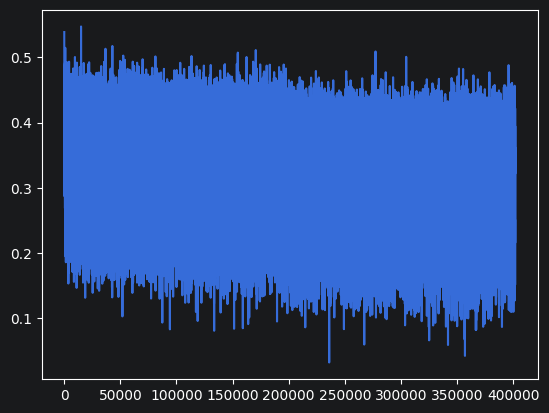

In [72]:
plt.plot(loss_i)

In [73]:
@torch.no_grad()
def split_loss(split):
  x,y = {
    'train': (X_tr, Y_tr),
    'val': (X_dev, Y_dev),
    'test': (X_test, Y_test),
  }[split]
  emb = C[x]
  embcat = emb.view(emb.shape[0], -1)
  h_preact = embcat @ w1 + b1
  h_preact = bn_gain * (h_preact - bn_mean_running) / bn_std_running + bn_bias
  h = torch.tanh(h_preact)
  logits = h @ w2 + b2
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('test')

train 2.4242939949035645
test 2.4775733947753906
